# [Lab Session 3](fourier.ipynb)


In [19]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


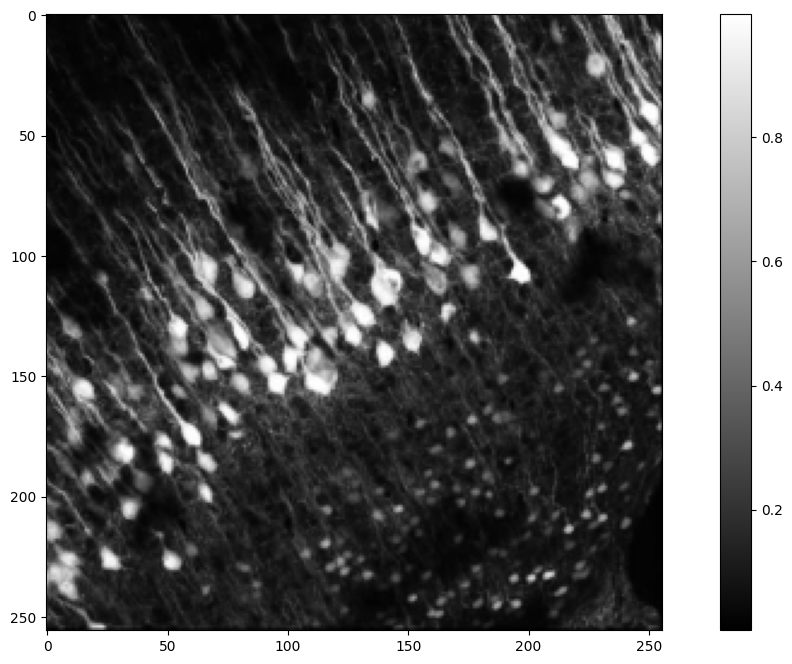

In [30]:
cell_img = plt.imread('data/cells.png')

cell_img_resized = resize(cell_img, (256, 256))

plt.figure(figsize=(15,8))
plt.imshow(cell_img_resized, 'gray')
plt.colorbar()

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [31]:
cell_ft = np.fft.fft2(cell_img)

print(cell_ft.dtype)

complex128


**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [22]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

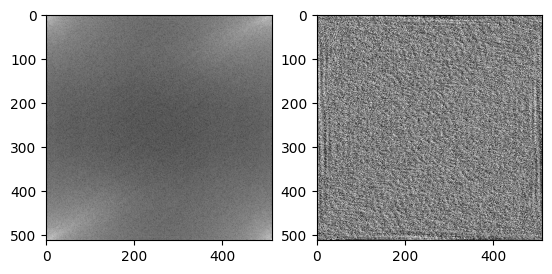

In [23]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


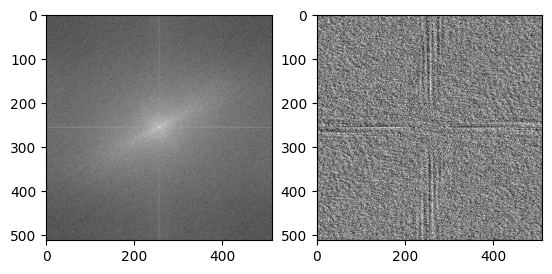

In [32]:
cell_ft_shift = np.fft.fftshift(cell_ft)

amplitude_shift = np.abs(cell_ft_shift)
phase_shift = np.angle(cell_ft_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_shift), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase_shift, 'gray')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


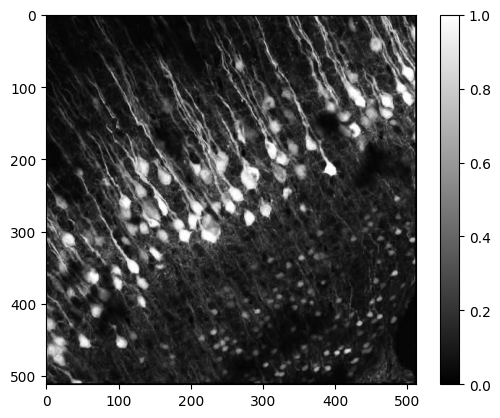

In [25]:
cell_ft_unshifted = np.fft.ifftshift(cell_ft_shift)

cell_restored_complex = np.fft.ifft2(cell_ft_unshifted)

cell_restored = cell_restored_complex.real

plt.figure()
plt.imshow(cell_restored, 'gray')
plt.colorbar()

---


**[Task 2 (a).]()** Load the brain MR image.


In [26]:
brain_mr = plt.imread('data/brain_mri.png')

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


In [27]:
brain_mr_ft = np.fft.fft2(brain_mr)

brain_mr_ft_shift = np.fft.fftshift(brain_mr_ft)

amplitude_shift_brain = np.abs(brain_mr_ft_shift)
phase_shift_brain = np.angle(brain_mr_ft_shift)

In [28]:
def to_complex_array(amplitude_shift_brain, phase_shift_brain):
    return amplitude_shift_brain * np.exp(1j * phase_shift_brain)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


In [34]:

merged_ft_shifted = to_complex_array(amplitude_shift_brain, phase_shift)

merged_ft = np.fft.ifftshift(merged_ft_shifted)

merged_img = np.fft.ifft2(merged_ft).real

plt.figure()
plt.imshow(merged_img, 'gray')
plt.colorbar()

ValueError: operands could not be broadcast together with shapes (256,256) (512,512) 

**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


In [17]:
merged_ft_shifted_2 = to_complex_array(amplitude_shift, phase_shift_brain)

merged_ft_2 = np.fft.ifftshift(merged_ft_shifted_2)

merged_img_2 = np.fft.ifft2(merged_ft_2).real

plt.figure()
plt.imshow(merged_img_2, 'gray')
plt.colorbar()

print("The phase carries more structural information.  Why: In part (c) (brain amplitude + cell phase), you can clearly recognize the cells, whereas in part (d) (cell amplitude + brain phase), you clearly recognize the brain. The phase encodes the spatial positions of edges and features (the structure of the image), while the amplitude only encodes how strongly each frequency is represented (overall contrast/intensity distribution).")

ValueError: operands could not be broadcast together with shapes (512,512) (256,256) 

---


**[Task 3 (a).]()** Create a lowpass filter mask.


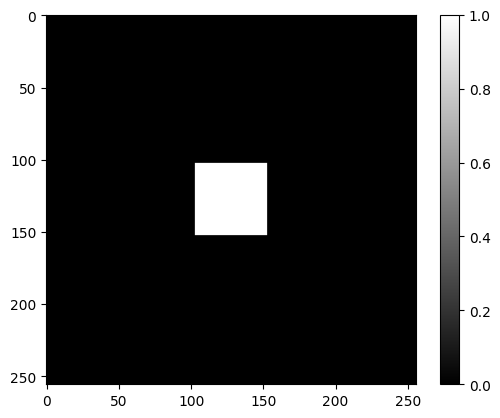

In [15]:
filter_window_size = 50

mask_lp = np.zeros(cell_img_resized.shape)

center_y = mask_lp.shape[0] // 2
center_x = mask_lp.shape[1] // 2
half_w = filter_window_size // 2

mask_lp[center_y - half_w : center_y + half_w, center_x - half_w : center_x + half_w] = 1

plt.figure()
plt.imshow(mask_lp, 'gray')
plt.colorbar()

**[Task 3 (b).]()** Create a highpass filter maks.


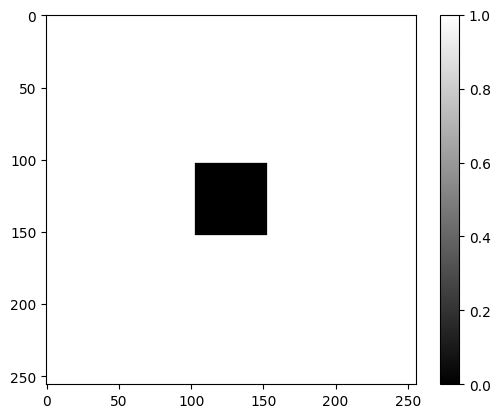

In [18]:
mask_hp = 1 - mask_lp

# Optional zum Überprüfen anzeigen:
plt.figure()
plt.imshow(mask_hp, 'gray')
plt.colorbar()

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


Due to high computational costs, we need to resize the image.


In [ ]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


**[Task 4 (f).]()** Round the arrays and compare them again.


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)
